In [ ]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("/content/credit_risk_dataset.csv")
pd.set_option('display.float_format', '{:,.2f}'.format)
df["person_income"] = df["person_income"].astype(int)

# Customer Analysis
The code below seperates the people who have defaulted on their loans so we can get an understanding of patterns that people who defaulted on their loans have in common. Some factors that we are looking at is their


*   Age
*   Income
*   Loan Intent
*   Loan Grade
*   Loan Amount
*   Loan Interest Rate
*   Loan's Percent of Income

In [ ]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,"32,581.00","32,581.00","31,686.00","32,581.00","29,465.00","32,581.00","32,581.00","32,581.00"
mean,27.73,"66,074.85",4.79,"9,589.37",11.01,0.22,0.17,5.80
std,6.35,"61,983.12",4.14,"6,322.09",3.24,0.41,0.11,4.06
min,20.00,"4,000.00",0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,"38,500.00",2.00,"5,000.00",7.90,0.00,0.09,3.00
50%,26.00,"55,000.00",4.00,"8,000.00",10.99,0.00,0.15,4.00
75%,30.00,"79,200.00",7.00,"12,200.00",13.47,0.00,0.23,8.00
max,144.00,"6,000,000.00",123.00,"35,000.00",23.22,1.00,0.83,30.00


In [ ]:
default_percentage = round(int((df['cb_person_default_on_file'] == 'Y').sum()) / len(df['cb_person_default_on_file']), 2)
print(f"Percent of people defaulting on their loans: {int(default_percentage * 100)}%")

Percent of people defaulting on their loans: 18%


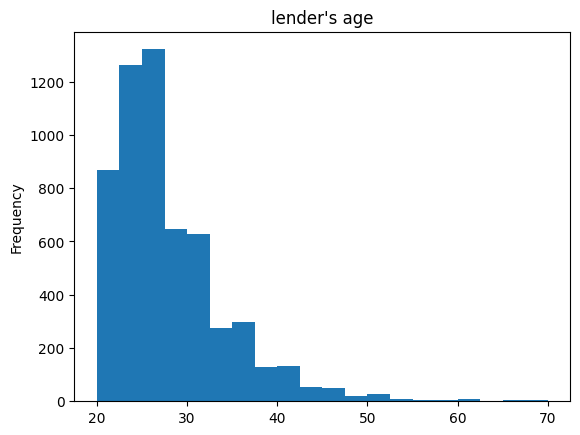

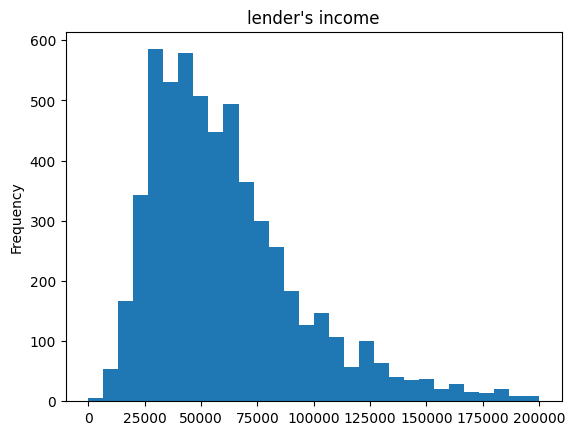

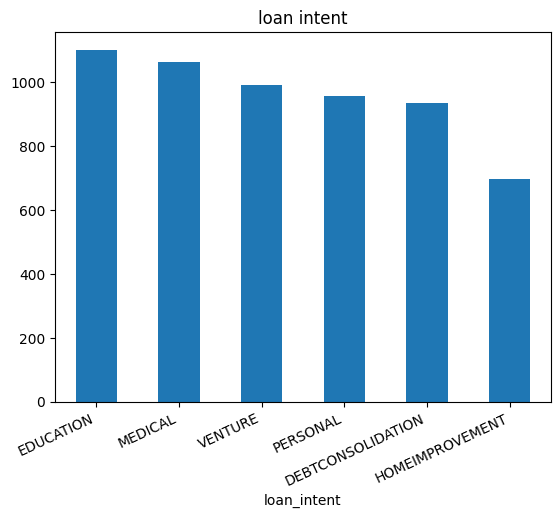

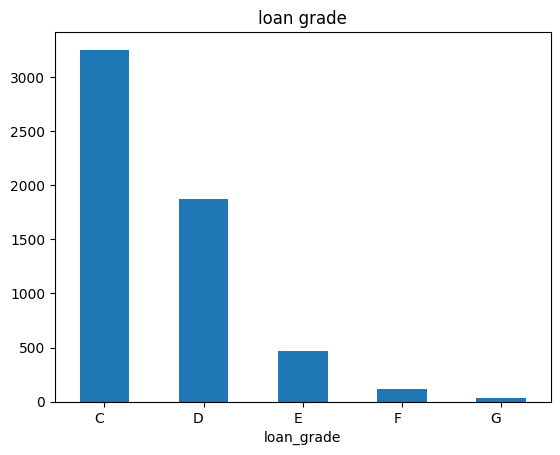

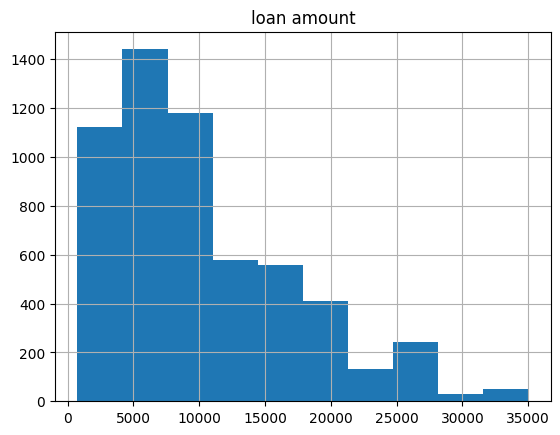

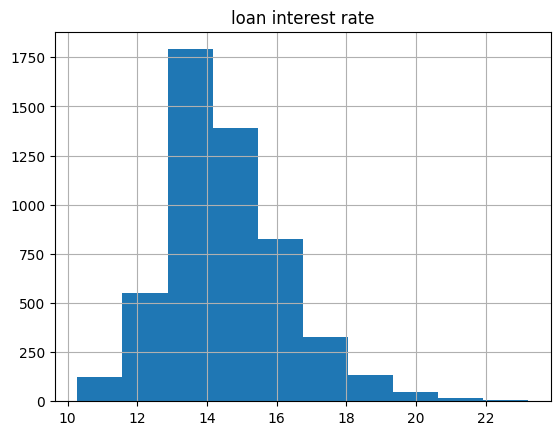

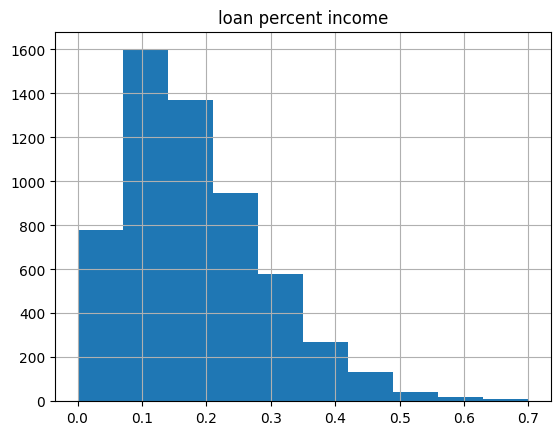

In [ ]:
default_df = df[df['cb_person_default_on_file'] == 'Y']

default_df['person_age'].plot(kind='hist', bins=20, title="lender's age")
plt.show()

default_df['person_income'].plot(kind='hist', bins=30, range=(0, 200_000), title="lender's income")
plt.show()

default_df['loan_intent'].value_counts().plot(kind='bar')
plt.xticks(rotation=25, ha='right')
plt.title("loan intent")
plt.show()

default_df['loan_grade'].value_counts().plot(kind='bar')
plt.xticks(rotation=0, ha='right')
plt.title("loan grade")
plt.show()

default_df['loan_amnt'].hist()
plt.title("loan amount")
plt.show()

default_df['loan_int_rate'].hist()
plt.title("loan interest rate")
plt.show()

default_df['loan_percent_income'].hist()
plt.title("loan percent income")
plt.show()

Most lenders who are defaulting are 20-30 years old, getting a loan for education or medical purposes, borrow around \$5,000-$10,000, have an interest rate of about 14%, none have a loan grade of a A or B, and their loan is 10%-25% of their income.

# Mitigating Risk in the future

## Random Forest prediction
To help mitigate risk in the future we will take in the loan recipient's information and use it to predict if they would be a good candidate to provide a loan to.

Random Forest Machine Learning models simply figure out what factors are the most important in determining an outcome and make a simple tree graph to follow and make a prediction. In this case the random forest model is predicting which loan recipients will default on ther loan repayments.

In [ ]:
from scipy.sparse import data
encoder = LabelEncoder()
df["person_home_ownership"] = encoder.fit_transform(df["person_home_ownership"])
df["loan_intent"] = encoder.fit_transform(df["loan_intent"])
df["loan_grade"] = encoder.fit_transform(df["loan_grade"])

features = ["person_age", "person_income", "person_home_ownership", "person_emp_length",	"loan_intent",	"loan_grade",	"loan_amnt",	"loan_int_rate",	"loan_percent_income"]
dependent = "loan_status"

X = df[features]
y = df[dependent]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

forest = RandomForestClassifier(max_depth=4, random_state = 10, n_estimators = 100, min_samples_leaf=5)
model = forest.fit(X_train, y_train)

y_pred = forest.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:\n", classification_rep)

Accuracy: 0.91

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.99      0.95      5072
           1       0.95      0.65      0.77      1445

    accuracy                           0.91      6517
   macro avg       0.93      0.82      0.86      6517
weighted avg       0.92      0.91      0.91      6517



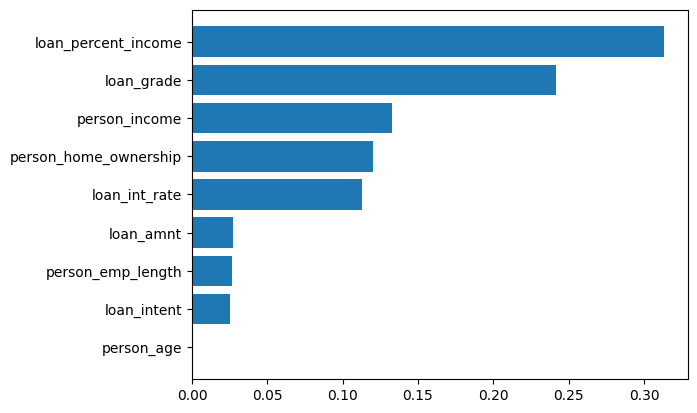

In [ ]:
feature_importance = list(zip(features,forest.feature_importances_))
feature_importance.sort(key = lambda x : x[1])
plt.barh([x[0] for x in feature_importance],[x[1] for x in feature_importance])
plt.show()

# Interpreting the model
The random forest model implemented reached an accuracy of 91% of determing which loan candidates will default on their loans and determined that the top three factors indiciding that was the loan's percentage of their income, the grade of the loan, and the income of the lender.


In [ ]:
estimator = model.estimators_[50]
estimator
model.estimators_[50].tree_.max_depth

fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (32,20), dpi=500)
sk.tree.plot_tree(estimator, filled=True, fontsize = 10, feature_names=features, class_names = True)
fig.savefig('DecisionTree.png')

#Simple loan calculator
This function predictes if a user is elegible for a loan based on the information that they provide.
Information needed:
* Their age
* Their income
* Home ownership status
* Employment length
* Loan intention
* Loan grade
* loan amount
* loan's interest rate

In [ ]:
def predict_loan_default(age, income, home_ownership, emp_length, loan_intent, loan_grade, loan_amnt, loan_int_rate):
  single_instance = np.array([age, income, home_ownership, emp_length, loan_intent, loan_grade, loan_amnt, loan_int_rate, loan_amnt / income])

  single_instance_2d = single_instance.reshape(1, -1)

  prediction = forest.predict(single_instance_2d)

  if prediction == 0:
    print("Horray, you have been approved!")
  else:
    print("Sorry, you have been rejected.")


age = int(input("Please enter your age. "))
income = int(input("Please enter your income. "))
home_ownership = int(input("Please enter your home ownership status. \n0 = Morgage, 1 = Other, 2 = Own, 3 = Rent "))
emp_length = int(input("Please enter your employment length in years. "))
loan_intent = int(input("Please choose your loan intention. \n0 = Debt Consolidation, 1 = Education, 2 = Home Improvement, 3 = Medical, 4 = Personal, 5 = Venture "))
loan_grade = int(input("What was the grade of loan you were approved for? \n# 0 = A, 1 = B, 2 = C, 3 = D, 4 = E, 5 = F, 6 = G "))
loan_amnt = int(input("Please enter your loan's amount. "))
loan_int_rate = loan_amnt / income if income != 0 else 0

predict_loan_default(age, income, home_ownership, emp_length, loan_intent, loan_grade, loan_amnt, loan_int_rate)

Please enter your age. 18
Please enter your income. 6000
Please enter your home ownership status. 
0 = Morgage, 1 = Other, 2 = Own, 3 = Rent 1
Please enter your employment length in years. 2
Please choose your loan intention. 
0 = Debt Consolidation, 1 = Education, 2 = Home Improvement, 3 = Medical, 4 = Personal, 5 = Venture 1
What was the grade of loan you were approved for? 
# 0 = A, 1 = B, 2 = C, 3 = D, 4 = E, 5 = F, 6 = G 0
Please enter your loan's amount. 12000
Sorry, you have been rejected.
